# Ⅰ第4回 演習2 5 回回して「差がある」と言えるか

**問い**：演習1 の MLP と CNN の差は，乱数の種（シード）を変えても残るか．

演習1 で自分が書いた③〜⑫と同じ手順を関数 `run` にまとめてある（`common/mydata.py`）．MLP と CNN をシード 0〜4 で 5 回ずつ回す．1 回 1〜数秒．
乱数の使い方が少し違うので，シード 0 の値が演習1 と一致しないことがある．
シードを変えると，**データの分け方・重みの初期値・ミニバッチの順** が変わる．写真とモデルの形は変わらない．

## (0) 番号の設定

In [1]:
# ===== (0) 番号の設定 =====
MEMBER_NO = 3                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/hinata/AI_TD


## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．

- CNN の 5 回のテスト正解率は，一番低い回と高い回で何ポイント離れるか：5ポイント
- 5 回の平均で，CNN と MLP に「差がある」と言えるか：差があると言える

## (確認) 差の判定

授業ページの「演習2」を読んでから答える．**全問正解すると先へ進める**（ちがうとヒントが出る）．

**Q1**　シードを変えると変わらないものはどれか
- ア データの分け方
- イ 重みの初期値
- ウ 写真そのもの

**Q2**　テスト画像が 30 枚のとき，1 枚の正解・不正解でテスト正解率は何ポイント動くか
- ア 1 ポイント
- イ 約 3.3 ポイント
- ウ 30 ポイント

**Q3**　平均の差 ÷ 標準偏差 が 0.5 だった．どう判定するか
- ア 差がある
- イ 差があるとは言えない
- ウ 標準偏差が小さいので信じられる

In [3]:
from common.todo import checkpoint, quiz_check
# ▼ 下の " " の中に，ア・イ・ウのどれかを書いて実行する
Q1 = "ウ"
Q2 = "イ"
Q3 = "イ"
quiz_check({    # 2 つ目の値は答え合わせ用の暗号（答えは書いていない）
    "Q1": (Q1, "eb47a8e6", "シードで変わるのは分け方・初期値・順．写真は同じ"),
    "Q2": (Q2, "af2c0979", "100 ÷ 30 ≒ 3.3．テストが少ないと 1 枚で大きく動く"),
    "Q3": (Q3, "d0859473", "差がばらつきの半分しかない．1 未満なら「差があるとは言えない」"),
})

Q1：正解．シードで変わるのは分け方・初期値・順．写真は同じ
Q2：正解．100 ÷ 30 ≒ 3.3．テストが少ないと 1 枚で大きく動く
Q3：正解．差がばらつきの半分しかない．1 未満なら「差があるとは言えない」
全問正解．実験に進んでよい


## (1) MLP と CNN をシード 0〜4 で回す

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from common.device import get_device
from common.logger import ResultLogger
from common.mydata import image_dir, run, diff_ratio, verdict
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

device = get_device()
IMAGE_DIR = image_dir()
SEEDS = [0, 1, 2, 3, 4]
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d4", exercise="ex2", device=device)
rows = []
for kind in ["MLP", "CNN"]:
    for seed in SEEDS:
        r = run(kind, seed=seed, root=IMAGE_DIR, device=device)
        logger.log_many({k: r[k] for k in ["test_acc", "val_acc_best", "train_sec"]}, condition=f"{IMAGE_DIR.name}_{kind}", seed=seed)
        rows.append({"モデル": kind, "シード": seed, "テスト正解率": r["test_acc"] * 100, "学習時間(秒)": r["train_sec"]})
        print(f"{kind} シード {seed}：テスト正解率 {r['test_acc'] * 100:.1f}%  ({r['train_sec']:.1f} 秒)")
df = pd.DataFrame(rows)
print(f"テストは {r['n_test']} 枚．1 枚で {100 / r['n_test']:.1f} ポイント動く")

assets/mydata/ が無いので，ケーブル画像（assets/cable1/）で進めます
MLP シード 0：テスト正解率 80.0%  (5.1 秒)
MLP シード 1：テスト正解率 43.3%  (5.2 秒)
MLP シード 2：テスト正解率 80.0%  (4.9 秒)
MLP シード 3：テスト正解率 80.0%  (5.2 秒)
MLP シード 4：テスト正解率 83.3%  (5.3 秒)
CNN シード 0：テスト正解率 86.7%  (2.5 秒)
CNN シード 1：テスト正解率 73.3%  (2.4 秒)
CNN シード 2：テスト正解率 86.7%  (2.5 秒)
CNN シード 3：テスト正解率 90.0%  (2.4 秒)
CNN シード 4：テスト正解率 83.3%  (2.5 秒)
テストは 30 枚．1 枚で 3.3 ポイント動く


## (2) 平均・標準偏差と，差 ÷ 標準偏差

モデル   MLP   CNN
シード            
0    80.0  86.7
1    43.3  73.3
2    80.0  86.7
3    80.0  90.0
4    83.3  83.3

       平均  標準偏差    最小    最大
モデル                        
CNN  84.0   6.4  73.3  90.0
MLP  73.3  16.8  43.3  83.3

平均の差（CNN − MLP）+10.7 ポイント ÷ 標準偏差 12.7 = 0.8 → 差があるとは言えない
シード 0 だけなら：CNN − MLP = +6.7 ポイント


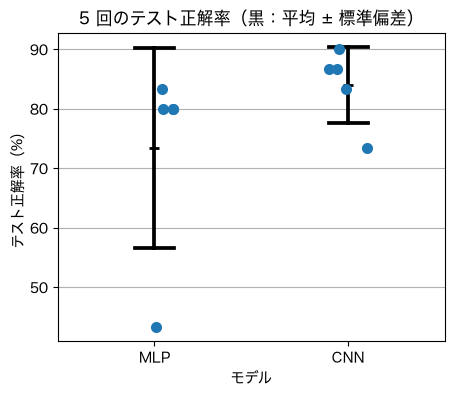

In [7]:
table = df.pivot(index="シード", columns="モデル", values="テスト正解率")[["MLP", "CNN"]]
print(table.round(1).to_string())
print()
print(df.groupby("モデル")["テスト正解率"].agg(平均="mean", 標準偏差="std", 最小="min", 最大="max").round(1).to_string())

diff, sd, ratio = diff_ratio(table["MLP"], table["CNN"])
print(f"\n平均の差（CNN − MLP）{diff:+.1f} ポイント ÷ 標準偏差 {sd:.1f} = {ratio:.1f} → {verdict(ratio)}")
print(f"シード 0 だけなら：CNN − MLP = {table.loc[0, 'CNN'] - table.loc[0, 'MLP']:+.1f} ポイント")

plt.figure(figsize=(5, 4))
sns.stripplot(data=df, x="モデル", y="テスト正解率", size=8, jitter=0.1)
sns.pointplot(data=df, x="モデル", y="テスト正解率", errorbar="sd", color="black", markers="_", capsize=0.2, linestyle="none")
plt.title("5 回のテスト正解率（黒：平均 ± 標準偏差）"); plt.ylabel("テスト正解率（%）"); plt.grid(True, axis="y")
plt.show()

## ✋ 止まる 1：ここから先へは，グループ全員がそろってから進む

**問い**：メンバーの中で「差がある」と言えた人と言えなかった人がいたか．データの何が違ったか

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：自分の (2) の表とグラフを見せ，クラス・枚数・差 ÷ 標準偏差を言う．根拠になる所：(2) の標準偏差と，1 枚で何ポイント動くか
3. 全員が下のセルの `CP1 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [9]:
# 問い：メンバーの中で「差がある」と言えた人と言えなかった人がいたか．データの何が違ったか
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP1 = "メンバーによってシードの分け方が違ったため、テストの分布が変わり、差があるかどうかの判定が変わった。"
checkpoint(CP1, "止まる 1")

止まる 1 OK：メンバーによってシードの分け方が違ったため、テストの分布が変わり、差があるかどうかの判定が変わった。


## (3) 第1〜3回から持ち越した問いの答え合わせ

教員が同じ条件で回した値（第2回は 3 回．ほかは 5 回）．

In [10]:
carry = [   # (問い, 比べたもの, 指標, A の値, B の値)
    ("第1回 ケーブル画像", "MLP → CNN", "テスト正解率(%)", [83.3, 76.7, 76.7, 83.3, 80.0], [80.0, 73.3, 83.3, 90.0, 90.0]),
    ("第2回 映画レビュー", "MLP → Transformer", "テスト正解率(%)", [80.40, 80.56, 80.67], [80.94, 80.67, 81.05]),
    ("第3回 正則化", "なし → Dropout", "検証正解率の最高値(%)", [81.20, 81.98, 81.42, 82.12, 81.00], [81.65, 82.41, 82.14, 82.73, 81.26]),
    ("第3回 正則化", "なし → 早期終了", "検証損失", [0.99, 0.94, 0.96, 0.97, 0.96], [0.57, 0.56, 0.57, 0.55, 0.56]),
]
for name, pair, metric, a, b in carry:
    d, s, r = diff_ratio(a, b)
    print(f"{name}｜{pair}｜{metric}：差 {d:+.2f} ÷ 標準偏差 {s:.2f} = {r:.1f} → {verdict(r)}")

第1回 ケーブル画像｜MLP → CNN｜テスト正解率(%)：差 +3.32 ÷ 標準偏差 5.53 = 0.6 → 差があるとは言えない
第2回 映画レビュー｜MLP → Transformer｜テスト正解率(%)：差 +0.34 ÷ 標準偏差 0.17 = 2.0 → 差がある
第3回 正則化｜なし → Dropout｜検証正解率の最高値(%)：差 +0.49 ÷ 標準偏差 0.54 = 0.9 → 差があるとは言えない
第3回 正則化｜なし → 早期終了｜検証損失：差 -0.40 ÷ 標準偏差 0.01 = 28.4 → 差がある


## (4) 考察（提出）

このセルをダブルクリックして，＿＿ に書き込む（それぞれ 1〜2 文）．

1. 予測と比べて,当たったこと・外れたこと:どちらも外れた。CNN の 5 回の最高と最低は 90.0% と 73.3% で 16.7 ポイント離れ,予測の 5 ポイントよりずっと大きかった。「差があると言える」という予測も,実際は言えなかった。
2. 自分のデータで,CNN と MLP に差があると言えたか.シード 0 だけの結論と同じだったか:CNN は平均 84.0%(標準偏差 6.4),MLP は 73.3%(標準偏差 16.8)で,差 10.7 ÷ 標準偏差 約 12.7 = 約 0.8 なので「差があるとは言えない」。シード 0 だけだと CNN が 6.7 ポイント上で良く見えたが,シード 1 で MLP が 43.3% に落ちるなどばらつきが大きく,結論は同じではなかった。
3. (3) で,第1回(差 3.3 ポイント)と第2回(差 0.4 ポイント)の判定が逆になったのはなぜか.テストの枚数に注目して書く:ケーブル画像はテストが 30 枚で,1 枚の違いで 3.3 ポイント動くため,3.3 ポイントの差は 1 枚分でしかなく,標準偏差(5.5)の方が大きくて「差があるとは言えない」になった。映画レビューはテストが多く,標準偏差が 0.17 と小さいので,0.34 ポイントの差でもばらつきの 2 倍となり「差がある」になった。